# CodeAlpha Task 4

## Import some libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Install vadersentiment

In [2]:
%pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.


## Creating Sample Customer Review Dataset

In [3]:
reviews = [
    "This product is amazing and works perfectly.",
    "I absolutely love this product.",
    "The quality is excellent and worth the money.",
    "Very happy with my purchase.",
    "The delivery was fast and the product is great.",
    "Amazing experience, I would definitely recommend it.",
    "The product is good and useful.",
    "I am satisfied with the quality.",
    "Excellent service and friendly support.",
    "This is one of the best products I have bought.",
    
    "The product is terrible and completely useless.",
    "I am very disappointed with this purchase.",
    "The quality is extremely poor.",
    "Worst product I have ever bought.",
    "The delivery was late and the product was damaged.",
    "I hate this product.",
    "Very bad experience.",
    "The product stopped working after one day.",
    "Customer service was terrible.",
    "I would not recommend this product to anyone.",
    
    "The product is okay.",
    "It is neither good nor bad.",
    "The quality is average.",
    "The product works as expected.",
    "Delivery was on time.",
    "I received the product today.",
    "It is a normal product for its price.",
    "The packaging was standard.",
    "The product has some good and some bad features.",
    "My experience was average."
]

df_reviews = pd.DataFrame({"Review": reviews})

df_reviews.head()

,Review
0,This product is amazing and works perfectly.
1,I absolutely love this product.
2,The quality is excellent and worth the money.
3,Very happy with my purchase.
4,The delivery was fast and the product is great.


## Performing Sentiment Analysis Using VADER

In [4]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

df_reviews["Sentiment_Score"] = df_reviews["Review"].apply(
    lambda x: analyzer.polarity_scores(x)["compound"]
)

df_reviews.head()

,Review,Sentiment_Score
0,This product is amazing and works perfectly.,0.8402
1,I absolutely love this product.,0.6697
2,The quality is excellent and worth the money.,0.6808
3,Very happy with my purchase.,0.6115
4,The delivery was fast and the product is great.,0.6249


def get_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df_reviews["Sentiment"] = df_reviews["Sentiment_Score"].apply(get_sentiment)

df_reviews.head(10)

## Counting Sentiment

In [6]:
sentiment_counts = df_reviews["Sentiment"].value_counts()

print(sentiment_counts)

Sentiment
Negative    12
Positive    11
Neutral      7
Name: count, dtype: int64


# Data Visualization

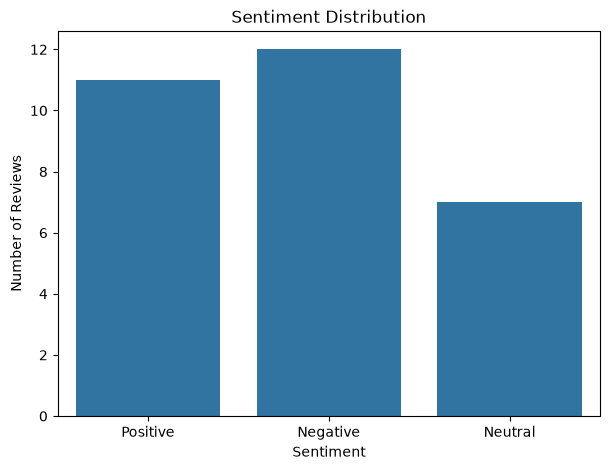

In [7]:
plt.figure(figsize=(7,5))

sns.countplot(data=df_reviews, x="Sentiment")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

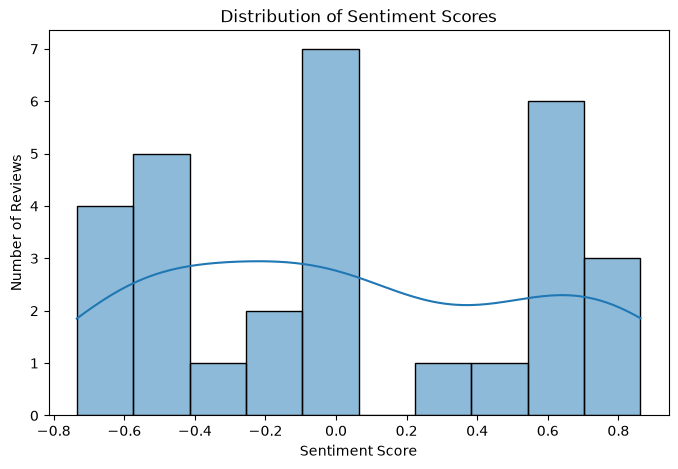

In [8]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df_reviews,
    x="Sentiment_Score",
    bins=10,
    kde=True
)

plt.title("Distribution of Sentiment Scores")
plt.xlabel("Sentiment Score")
plt.ylabel("Number of Reviews")
plt.show()

In [9]:
average_sentiment = df_reviews.groupby("Sentiment")["Sentiment_Score"].mean()

print(average_sentiment)

Sentiment
Negative   -0.476825
Neutral     0.000000
Positive    0.646800
Name: Sentiment_Score, dtype: float64


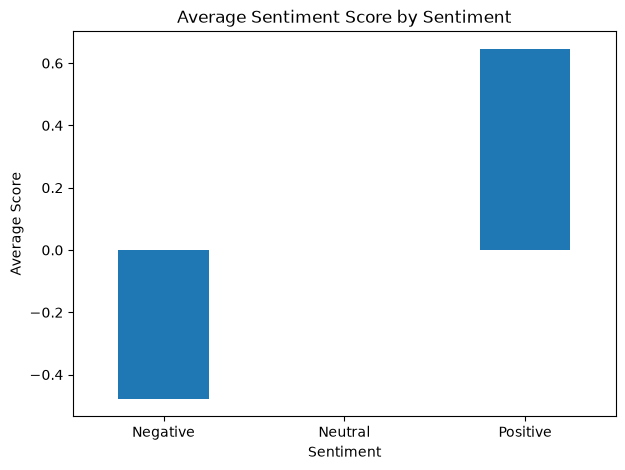

In [10]:
average_sentiment.plot(kind="bar", figsize=(7,5))

plt.title("Average Sentiment Score by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.show()

## Display Postive, Negative, & Neutral Review

In [11]:
positive_reviews = df_reviews[df_reviews["Sentiment"] == "Positive"]
negative_reviews = df_reviews[df_reviews["Sentiment"] == "Negative"]
neutral_reviews = df_reviews[df_reviews["Sentiment"] == "Neutral"]

print("Positive Reviews:")
print(positive_reviews[["Review", "Sentiment_Score"]])

print("\nNegative Reviews:")
print(negative_reviews[["Review", "Sentiment_Score"]])

print("\nNeutral Reviews:")
print(neutral_reviews[["Review", "Sentiment_Score"]])

Positive Reviews:
                                               Review  Sentiment_Score
0        This product is amazing and works perfectly.           0.8402
1                     I absolutely love this product.           0.6697
2       The quality is excellent and worth the money.           0.6808
3                        Very happy with my purchase.           0.6115
4     The delivery was fast and the product is great.           0.6249
5   Amazing experience, I would definitely recomme...           0.8402
6                     The product is good and useful.           0.7003
7                    I am satisfied with the quality.           0.4215
8             Excellent service and friendly support.           0.8625
9     This is one of the best products I have bought.           0.6369
20                               The product is okay.           0.2263

Negative Reviews:
                                               Review  Sentiment_Score
10    The product is terrible and comple

## Result & Analysis

In [12]:
print("========== SENTIMENT ANALYSIS FINDINGS ==========")

print("\nTotal Reviews:", len(df_reviews))

print("\nSentiment Counts:")
print(df_reviews["Sentiment"].value_counts())

print("\nMost Common Sentiment:")
print(df_reviews["Sentiment"].value_counts().idxmax())

print("\nAverage Sentiment Score:")
print(df_reviews["Sentiment_Score"].mean())

========== SENTIMENT ANALYSIS FINDINGS ==========

Total Reviews: 30

Sentiment Counts:
Sentiment
Negative    12
Positive    11
Neutral      7
Name: count, dtype: int64

Most Common Sentiment:
Negative

Average Sentiment Score:
0.046430000000000006


## Conclusion

Sentiment Analysis was performed on customer reviews using VADER sentiment analysis.

The reviews were classified into three categories: Positive, Negative, and Neutral.

The analysis helped identify the overall sentiment of the customer reviews.
The sentiment distribution and sentiment scores were visualized using different
charts to understand the pattern of customer opinions.

This analysis can help businesses understand customer feedback and improve
their products and services.